# Baseline 2 — Experiment Hub: Class-Level Calibration & Error Investigation

**ONE notebook / ONE Run All / NO new model training.**

**What this run covers:**
1. Exp12: post-hoc **crop-prior** / **disease-prior** / **combined class-level** adjustments derived only from `train_fit` counts.
2. Compare mild per-class adjustments with optional **seen-pair γ** penalties on the exact **9,625 all-pairs** catalogue.
3. Investigate **which images γ=6 fixes vs breaks**, not just net accuracy.
4. Report a cautious **internal tuning / check split** for calibration choices (not an independent test: checkpoints and earlier sweeps already used these development images).
5. Automatically save machine-readable sweeps, figures and a **leader summary** under one fresh output folder.

**NOT included in Run All:** ResNet-50 retraining, α=0.5 training, class-balanced-loss training, Stage 2, official test, candidate-333 restriction, new dataset splits. Those are separate controlled hypotheses; record them in the plan at the end, not as unverified results.

**Where:** Save this notebook directly in `C:\AML\ML_Project\Baseline2` next to `evaluate.py` and `model_resnet50.py`. It reuses Exp11 **saved raw logits** (so normally no GPU computation at all). When Exp11 caches are not available, the notebook stops with precise instructions instead of silently training or accessing test data.

## 1. Configuration and safety checks

- Existing Exp11 caches: `outputs/exp11_calibration/` containing four `.npz` files.
- Only development `train_fit`, `val_seen`, `val_unseen` may be accessed.
- New output: `outputs/exp12_class_calibration/`; never rename old folders or overwrite output.
- **Run All** once. If you need to repeat the run, change `RUN_ID` to a new name such as `exp12_class_calibration_v2`.

In [1]:
from pathlib import Path
import hashlib, json, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from evaluate import validate_development_splits, make_candidates

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / 'splits_v2'
OUTPUT_ROOT = PROJECT_DIR / 'outputs'
RAW_DIR = OUTPUT_ROOT / 'exp11_calibration'
RUN_ID = 'exp12_class_calibration'  # For reruns, choose a NEW ID. Never overwrite existing reports.
OUT_DIR = OUTPUT_ROOT / RUN_ID
SOURCES = ['exp09', 'exp10']
SPLITS = ['val_seen', 'val_unseen']
SEED_FOR_INTERNAL_CHECK = 2026
CALIBRATION_TUNE_FRACTION = 0.60
SMOOTHING_PSEUDOCOUNT = 1.0   # fixed in advance, NOT tuned in this run

assert PROJECT_DIR.name.lower() == 'baseline2', f'Open the Baseline2 folder, not: {PROJECT_DIR}'
assert SPLIT_DIR.is_dir(), f'Missing split folder: {SPLIT_DIR}'
assert not OUT_DIR.exists(), f'Output already exists: {OUT_DIR}. Choose a NEW RUN_ID.'
for source in SOURCES:
    for split in SPLITS:
        f = RAW_DIR / f'{source}_{split}_raw_logits.npz'
        assert f.is_file(), f'Missing existing Exp11 logits: {f}. Run Exp11 only if caches are absent.'
print('PREFLIGHT OK: reusing saved Exp11 raw logits; NO GPU or training required.')
print('Output:', OUT_DIR)

PREFLIGHT OK: reusing saved Exp11 raw logits; NO GPU or training required.
Output: c:\AML\ML_Project\Baseline2\outputs\exp12_class_calibration


## 2. Load validated development metadata, raw logits and training-only priors

No class prior is computed from validation labels. The validation IDs are used only to measure prediction accuracy.

In [2]:
frames, split_report = validate_development_splits(SPLIT_DIR)
assert split_report['counts'] == {'train_fit':6905, 'val_seen':695, 'val_unseen':400}
CANDIDATES = make_candidates('all_pairs')
assert tuple(CANDIDATES.shape) == (9625,2)
all_pairs = CANDIDATES.numpy().astype(np.int64)
pair_c = all_pairs[:, 0]
pair_d = all_pairs[:, 1]
train_pairs = set(map(tuple, frames['train_fit'][['crop_id','disease_id']].to_numpy(dtype=np.int64)))
seen_pair_mask = np.array([tuple(x) in train_pairs for x in all_pairs], dtype=bool)
assert int(seen_pair_mask.sum()) == 313

crop_counts = np.bincount(frames['train_fit']['crop_id'].to_numpy(dtype=np.int64),minlength=55)
disease_counts = np.bincount(frames['train_fit']['disease_id'].to_numpy(dtype=np.int64),minlength=175)
assert (crop_counts > 0).all() and (disease_counts > 0).all()
assert crop_counts.sum()==disease_counts.sum()==6905

def make_smoothed_log_prior(counts,pseudocount):
    p=(counts.astype(np.float64)+pseudocount)/(counts.sum()+len(counts)*pseudocount)
    return np.log(p).astype(np.float32)

log_crop_prior=make_smoothed_log_prior(crop_counts,SMOOTHING_PSEUDOCOUNT)
log_disease_prior=make_smoothed_log_prior(disease_counts,SMOOTHING_PSEUDOCOUNT)

raw={}
for source in SOURCES:
    raw[source]={}
    for split in SPLITS:
        fn=RAW_DIR/f'{source}_{split}_raw_logits.npz'
        with np.load(fn,allow_pickle=False) as z:
            obj={k:z[k].copy() for k in z.files}
        n=len(frames[split]); assert obj['crop_logits'].shape==(n,55)
        assert obj['disease_logits'].shape==(n,175)
        for field in ['crop_ids','disease_ids','filenames']:
            assert field in obj, f'{fn.name} missing {field}'
        assert np.array_equal(obj['crop_ids'],frames[split]['crop_id'].to_numpy(dtype=np.int64))
        assert np.array_equal(obj['disease_ids'],frames[split]['disease_id'].to_numpy(dtype=np.int64))
        assert np.array_equal(obj['filenames'].astype(str),frames[split]['filename'].astype(str).to_numpy())
        raw[source][split]=obj
print('Verified 6,905 train-fit, 695 seen-validation, 400 unseen-validation; 9,625 candidate pairs.')
print('Training-only frequency range: crops',crop_counts.min(),crop_counts.max(),
      '| diseases',disease_counts.min(),disease_counts.max())
print('All four cached logits arrays match the canonical development split.')

Verified 6,905 train-fit, 695 seen-validation, 400 unseen-validation; 9,625 candidate pairs.
Training-only frequency range: crops 2 1007 | diseases 1 1417
All four cached logits arrays match the canonical development split.


## 3. Shared scoring and internal calibration/check masks

**Calibration equation** (all settings use the same stored model logits):

\[
S'(c,d)=\log P(c\mid x)+\log P(d\mid x)-	au_c\log\pi_c-	au_d\log\pi_d-\gamma\,\mathbf{1}[(c,d)\in C_{train}].
\]

Here `π` is calculated **only from training-fit counts** with pseudocount 1.0. γ=0, τc=0, τd=0 is the control. A uniform γ≥0 is expected to trade seen for unseen; crop/disease class-level corrections *might* improve both but are not guaranteed.

For context, Exp11 reproduced Exp10's uncali­brated seen score within **one image of 695** (73.09% from logits versus 73.24% in saved training-time metrics). We explicitly report this discrepancy; we do **not** claim bit-for-bit reproduction or silently correct it. All new comparisons within this notebook use the **same saved logits**.

In [3]:
def log_softmax_np(x):
    x=np.asarray(x,dtype=np.float32)
    mx=x.max(axis=1,keepdims=True)
    return x-mx-np.log(np.exp(x-mx).sum(axis=1,keepdims=True))

def predict_pair(cache,tau_c=0.0,tau_d=0.0,gamma=0.0,chunk=64):
    """Return all-pairs predictions from cached logits; no training, no test leakage."""
    assert tau_c>=0 and tau_d>=0 and gamma>=0
    c=log_softmax_np(cache['crop_logits'])-np.float32(tau_c)*log_crop_prior[None,:]
    d=log_softmax_np(cache['disease_logits'])-np.float32(tau_d)*log_disease_prior[None,:]
    n=len(c)
    pred_c=np.empty(n,dtype=np.int64); pred_d=np.empty(n,dtype=np.int64)
    # Non-zero gamma is genuinely pair-dependent; score all 9,625 candidates in manageable chunks.
    if gamma==0:
        # Full Cartesian product: additive score argmax factorises (except numerical ties).
        pred_c=c.argmax(axis=1).astype(np.int64)
        pred_d=d.argmax(axis=1).astype(np.int64)
    else:
        for start in range(0,n,chunk):
            end=min(n,start+chunk)
            scores=c[start:end,pair_c]+d[start:end,pair_d]
            scores[:,seen_pair_mask]-=np.float32(gamma)
            ix=scores.argmax(axis=1)
            pred_c[start:end]=pair_c[ix]
            pred_d[start:end]=pair_d[ix]
    return pred_c,pred_d,c.argmax(axis=1),d.argmax(axis=1)

def one_accuracy(y,p):return float(np.mean(np.asarray(y)==np.asarray(p)))
def hm(a,b):return 0. if a+b==0 else 2*a*b/(a+b)

def membership_tune_mask(filenames):
    """Stable hash split; still NOT an independent test after prior development experimentation."""
    nums=[]
    for name in filenames:
        key=f'{SEED_FOR_INTERNAL_CHECK}|{name}'.encode('utf-8')
        nums.append(int(hashlib.sha256(key).hexdigest()[:12],16)/float(16**12))
    mask=np.asarray(nums)<CALIBRATION_TUNE_FRACTION
    assert mask.any() and (~mask).any()
    return mask

masks={s:membership_tune_mask(raw['exp09'][s]['filenames']) for s in SPLITS}
for split in SPLITS:
    assert np.array_equal(raw['exp09'][split]['filenames'],raw['exp10'][split]['filenames'])
    print(split, 'tune:',int(masks[split].sum()),'internal check:',int((~masks[split]).sum()))

# Synthetic tests: prior-zero argmax, gamma restriction, metric identities.
toy={'crop_logits':np.zeros((2,55),np.float32),
     'disease_logits':np.zeros((2,175),np.float32)}
toy['crop_logits'][0,0]=7; toy['crop_logits'][1,1]=7
toy['disease_logits'][:,0]=7
pred_c,pred_d,_,_=predict_pair(toy,0,0,0)
assert list(zip(pred_c.tolist(),pred_d.tolist()))==[(0,0),(1,0)]
assert abs(hm(.5,.5)-.5)<1e-12 and hm(0,.1)==0
for key in SOURCES:
    for split in SPLITS:
        obj=raw[key][split]
        a,b,_,_=predict_pair(obj,0,0,0)
        print(f'{key:5s} {split:10s} raw-logits composition Top-1: '+
              f'{np.mean((a==obj["crop_ids"]) & (b==obj["disease_ids"])):.4%}')
# Compare with original saved Stage-1 metrics without hiding the known one-image discrepancy.
SOURCE_METRIC_FOLDERS = {
    'exp09': OUTPUT_ROOT / 'b2_resnet50_exp09_b1matched_seed42',
    'exp10': OUTPUT_ROOT / 'exp10',
}
for src, folder in SOURCE_METRIC_FOLDERS.items():
    fn=folder/'validation_metrics.json'
    if fn.is_file():
        original=json.loads(fn.read_text(encoding='utf8'))
        for split,key in [('val_seen','seen'),('val_unseen','unseen')]:
            obj=raw[src][split]
            c,d,_,_=predict_pair(obj,0,0,0)
            hits=int(((c==obj['crop_ids'])&(d==obj['disease_ids'])).sum())
            n=len(obj['crop_ids'])
            expected=int(round(float(original[key]['composition_top1'])*n))
            diff=abs(hits-expected)
            print(f'{src} {split}: cached-logit correct {hits}/{n}, original checkpoint metric {expected}/{n}, difference={diff} image(s)')
            if diff > 1:
                raise RuntimeError(f'Baseline reproduction differs by >1 image for {src}/{split}; stop and verify cached logits/preprocessing.')
    else:
        print('NOTE: original metrics missing for',src,'— continuing with internally consistent Exp11 cached logits only.')
print('Synthetic tests passed. All new comparisons share one consistent scoring procedure.')

val_seen tune: 421 internal check: 274
val_unseen tune: 239 internal check: 161
exp09 val_seen   raw-logits composition Top-1: 72.9496%
exp09 val_unseen raw-logits composition Top-1: 4.0000%
exp10 val_seen   raw-logits composition Top-1: 73.0935%
exp10 val_unseen raw-logits composition Top-1: 4.0000%
exp09 val_seen: cached-logit correct 507/695, original checkpoint metric 507/695, difference=0 image(s)
exp09 val_unseen: cached-logit correct 16/400, original checkpoint metric 16/400, difference=0 image(s)
exp10 val_seen: cached-logit correct 508/695, original checkpoint metric 509/695, difference=1 image(s)
exp10 val_unseen: cached-logit correct 16/400, original checkpoint metric 16/400, difference=0 image(s)
Synthetic tests passed. All new comparisons share one consistent scoring procedure.


## 4. EXP12 — Run class-level crop/disease prior calibration plus mild γ combinations

All runs are **post-hoc scoring on the same two stored checkpoints**. The grids are exploratory, not automatically a production recommendation. See the **tune/check** columns; the check subset is not a truly untouched test because the backbone and previous experiments used this development split.

In [4]:
# Finite predeclared grid: ~100 settings per model, does not retrain.
GRID=[('baseline',0.,0.,0.)]
GRID += [('crop_prior',v,0.,0.) for v in [0.025,0.05,0.1,0.2,0.35,0.5,0.75]]
GRID += [('disease_prior',0.,v,0.) for v in [0.025,0.05,0.1,0.2,0.35,0.5,0.75,1.]]
GRID += [('crop+disease_prior',tc,td,0.)
         for tc in [0.05,0.1,0.2,0.35,0.5]
         for td in [0.05,0.1,0.2,0.35,0.5]]
GRID += [('seen_pair_gamma',0.,0.,g) for g in [0.5,1.,2.,4.,6.]]
GRID += [('prior+gamma',tc,td,g)
         for tc in [0.,0.1,0.25]
         for td in [0.,0.1,0.25,0.5]
         for g in [1.,2.]]
# 70 options for each source: predictable, no parameter optimization beyond explicit grid.
assert len(GRID)==70

all_results=[]; pred_store={}
t0=time.perf_counter()
for source in SOURCES:
    pred_store[source]={}
    for method,tc,td,g in GRID:
        item={'source':source,'method':method,'crop_tau':tc,'disease_tau':td,'gamma':g}
        predictions={}
        for split in SPLITS:
            obj=raw[source][split]
            p_c,p_d,head_c,head_d=predict_pair(obj,tc,td,g)
            y_c,y_d=obj['crop_ids'],obj['disease_ids']
            correct=(p_c==y_c)&(p_d==y_d)
            predictions[split]=(p_c,p_d,correct,head_c,head_d)
            for k,mask in [('full',np.ones(len(y_c),dtype=bool)),('tune',masks[split]),('check',~masks[split])]:
                item[f'{k}_{split}_n']=int(mask.sum())
                item[f'{k}_{split}_accuracy']=float(correct[mask].mean())
            if split=='val_unseen':
                item['unseen_disease_top1']=one_accuracy(y_d,head_d)
                item['unseen_crop_top1']=one_accuracy(y_c,head_c)
                item['predicted_seen_pair_rate']=float(np.mean([tuple(x) in train_pairs for x in zip(p_c,p_d)]))
        for k in ['full','tune','check']:
            a=item[f'{k}_val_seen_accuracy'];b=item[f'{k}_val_unseen_accuracy']
            item[f'{k}_HM']=hm(a,b)
        item['full_unseen_correct_of_400']=int(predictions['val_unseen'][2].sum())
        all_results.append(item)
        if (method=='baseline') or (tc==0 and td==0 and g==6):
            pred_store[source][(method,tc,td,g)]=predictions
    print(source, 'completed',len(GRID),'post-hoc settings')
results=pd.DataFrame(all_results)
for source in SOURCES:
    sub=results[results.source==source]
    base=sub[sub.method=='baseline'].iloc[0]
    for col in ['full','tune','check']:
        idx=results.source==source
        results.loc[idx,f'{col}_seen_delta_pp']=(results.loc[idx,f'{col}_val_seen_accuracy']-base[f'{col}_val_seen_accuracy'])*100
        results.loc[idx,f'{col}_unseen_delta_pp']=(results.loc[idx,f'{col}_val_unseen_accuracy']-base[f'{col}_val_unseen_accuracy'])*100
        results.loc[idx,f'{col}_strict_pareto']=(
            (results.loc[idx,f'{col}_seen_delta_pp']>0)&(results.loc[idx,f'{col}_unseen_delta_pp']>0))

OUT_DIR.mkdir(parents=True,exist_ok=False)
results.to_csv(OUT_DIR/'all_calibration_settings.csv',index=False)
(OUT_DIR/'run_settings.json').write_text(json.dumps({
    'run_id':RUN_ID,'splits':split_report['sha256'], 'source_raw_logits':str(RAW_DIR),
    'priors':'crop+disease frequencies from train_fit only',
    'smoothing_pseudocount':SMOOTHING_PSEUDOCOUNT,
    'calibration_tune_fraction':CALIBRATION_TUNE_FRACTION,
    'hash_seed':SEED_FOR_INTERNAL_CHECK,
    'grid_size_per_checkpoint':len(GRID),'candidate_pairs':9625,'training_executed':False,
    'official_test_accessed':False,'stage2_executed':False},indent=2),encoding='utf8')
print('Sweep completed:',len(results),'model/parameter evaluations in',round(time.perf_counter()-t0,1),'seconds')
print('Best exploratory FULL-development HM (not independent test):')
display(results.sort_values('full_HM',ascending=False)[[
    'source','method','crop_tau','disease_tau','gamma',
    'full_val_seen_accuracy','full_val_unseen_accuracy','full_HM','full_strict_pareto']].head(10))

exp09 completed 70 post-hoc settings
exp10 completed 70 post-hoc settings
Sweep completed: 140 model/parameter evaluations in 3.2 seconds
Best exploratory FULL-development HM (not independent test):


,source,method,crop_tau,disease_tau,gamma,full_val_seen_accuracy,full_val_unseen_accuracy,full_HM,full_strict_pareto
115,exp10,seen_pair_gamma,0.00,0.00,6.0,0.463309,0.0825,0.140060,False
114,exp10,seen_pair_gamma,0.00,0.00,4.0,0.594245,0.0725,0.129233,False
45,exp09,seen_pair_gamma,0.00,0.00,6.0,0.460432,0.0675,0.117739,False
131,exp10,prior+gamma,0.10,0.50,2.0,0.654676,0.0625,0.114107,False
139,exp10,prior+gamma,0.25,0.50,2.0,0.650360,0.0625,0.114041,False
44,exp09,seen_pair_gamma,0.00,0.00,4.0,0.601439,0.0625,0.113233,False
127,exp10,prior+gamma,0.10,0.10,2.0,0.679137,0.0600,0.110259,False
135,exp10,prior+gamma,0.25,0.10,2.0,0.673381,0.0600,0.110182,False
129,exp10,prior+gamma,0.10,0.25,2.0,0.670504,0.0600,0.110144,False
137,exp10,prior+gamma,0.25,0.25,2.0,0.666187,0.0600,0.110085,False


## 5. Candidate selection on tuning subset; inspection on check subset

We pick highest tune-subset HM, plus a **Seen-preserving** choice with no more than 2 pp reduction in tune Seen accuracy. We then report check-subset performance. **This is not an independent test**: you have already trained/selected checkpoints and explored calibration using the complete development set. Do not claim an unbiased final result.

In [5]:
def pick_settings(table,source):
    sub=table[table.source==source].copy()
    best=sub.sort_values(['tune_HM','tune_val_seen_accuracy'],ascending=False).iloc[0]
    base=sub[sub.method=='baseline'].iloc[0]
    mild=sub[sub.tune_val_seen_accuracy>=base.tune_val_seen_accuracy-.02]
    best_mild=mild.sort_values(['tune_HM','tune_val_seen_accuracy'],ascending=False).iloc[0]
    return base,best,best_mild

picked=[]
for source in SOURCES:
    base,best,mild=pick_settings(results,source)
    for label,row in [('baseline',base),('highest_tune_HM',best),('seen_drop_at_most_2pp',mild)]:
        picked.append({
            'source':source,'selection':label,'method':row.method,
            'crop_tau':row.crop_tau,'disease_tau':row.disease_tau,'gamma':row.gamma,
            'tune_seen':row.tune_val_seen_accuracy,'tune_unseen':row.tune_val_unseen_accuracy,
            'tune_HM':row.tune_HM,'check_seen':row.check_val_seen_accuracy,
            'check_unseen':row.check_val_unseen_accuracy,'check_HM':row.check_HM,
            'full_seen':row.full_val_seen_accuracy,'full_unseen':row.full_val_unseen_accuracy,
            'full_HM':row.full_HM,
        })
selected=pd.DataFrame(picked)
selected.to_csv(OUT_DIR/'selected_settings_internal_check.csv',index=False)
display(selected)
for source in SOURCES:
    n=int(results[(results.source==source)&results.full_strict_pareto.fillna(False)].shape[0])
    print(source,'strict full-dev Seen & Unseen Pareto improvements found:',n)

,source,selection,method,crop_tau,disease_tau,gamma,tune_seen,tune_unseen,tune_HM,check_seen,check_unseen,check_HM,full_seen,full_unseen,full_HM
0,exp09,baseline,baseline,0.00,0.0,0.0,0.733967,0.029289,0.056330,0.722628,0.055901,0.103774,0.729496,0.0400,0.075841
1,exp09,highest_tune_HM,seen_pair_gamma,0.00,0.0,6.0,0.477435,0.058577,0.104352,0.434307,0.080745,0.136174,0.460432,0.0675,0.117739
2,exp09,seen_drop_at_most_2pp,prior+gamma,0.25,0.0,1.0,0.717340,0.033473,0.063961,0.718978,0.062112,0.114345,0.717986,0.0450,0.084692
3,exp10,baseline,baseline,0.00,0.0,0.0,0.722090,0.037657,0.071581,0.744526,0.043478,0.082159,0.730935,0.0400,0.075849
4,exp10,highest_tune_HM,seen_pair_gamma,0.00,0.0,6.0,0.489311,0.087866,0.148980,0.423358,0.074534,0.126753,0.463309,0.0825,0.140060
5,exp10,seen_drop_at_most_2pp,crop+disease_prior,0.50,0.2,0.0,0.710214,0.046025,0.086448,0.740876,0.043478,0.082136,0.722302,0.0450,0.084722


exp09 strict full-dev Seen & Unseen Pareto improvements found: 0
exp10 strict full-dev Seen & Unseen Pareto improvements found: 0


## 6. Why does γ=6 help unseen? Export actual recovered vs lost examples

The increase from 16/400 to 33/400 is a **net increase** of 17 correct images. The number recovered and the number newly broken can differ; this analysis counts both exactly. Outputs contain development image filenames only, no official test data.

In [6]:
flip_rows=[];flip_aggregate=[]
for source in SOURCES:
    baseline=pred_store[source][('baseline',0.,0.,0.)]
    calibrated=pred_store[source][('seen_pair_gamma',0.,0.,6.)]
    for split in SPLITS:
        obj=raw[source][split]
        bc,bd,bok,_,_=baseline[split]
        gc,gd,gok,_,_=calibrated[split]
        status=np.select([~bok&gok,bok&~gok,bok&gok],
                         ['recovered','lost','correct_both'],default='wrong_both')
        tmp=pd.DataFrame({
            'source':source,'split':split,'filename':obj['filenames'],
            'true_crop':obj['crop_ids'],'true_disease':obj['disease_ids'],
            'baseline_crop':bc,'baseline_disease':bd,
            'gamma6_crop':gc,'gamma6_disease':gd,
            'baseline_correct':bok,'gamma6_correct':gok,'transition':status})
        flip_rows.append(tmp)
        counts=tmp.transition.value_counts().to_dict()
        flip_aggregate.append({'source':source,'split':split,'n':len(tmp),
                               'recovered':counts.get('recovered',0),
                               'lost':counts.get('lost',0),
                               'correct_both':counts.get('correct_both',0),
                               'wrong_both':counts.get('wrong_both',0),
                               'net_change':int(gok.sum()-bok.sum())})
flips=pd.concat(flip_rows,ignore_index=True)
transitions=pd.DataFrame(flip_aggregate)
flips.to_csv(OUT_DIR/'gamma6_prediction_transitions.csv',index=False)
transitions.to_csv(OUT_DIR/'gamma6_transition_counts.csv',index=False)
display(transitions)
for source in SOURCES:
    corrected=flips[(flips.source==source)&(flips.split=='val_unseen')&(flips.transition=='recovered')]
    print(source, 'unseen newly correct by disease_id:', corrected.true_disease.value_counts().to_dict())

,source,split,n,recovered,lost,correct_both,wrong_both,net_change
0,exp09,val_seen,695,0,187,320,188,-187
1,exp09,val_unseen,400,11,0,16,373,11
2,exp10,val_seen,695,0,186,322,187,-186
3,exp10,val_unseen,400,17,0,16,367,17


exp09 unseen newly correct by disease_id: {139: 6, 14: 4, 9: 1}
exp10 unseen newly correct by disease_id: {139: 16, 9: 1}


## 7. Save comparison plots, weakest-class impact and leader summary

All improvement claims remain **exploratory development-only**. The reported HM gain is not an independent confirmation of generalisation, and the earlier Exp10 1-image mismatch is explicitly noted.

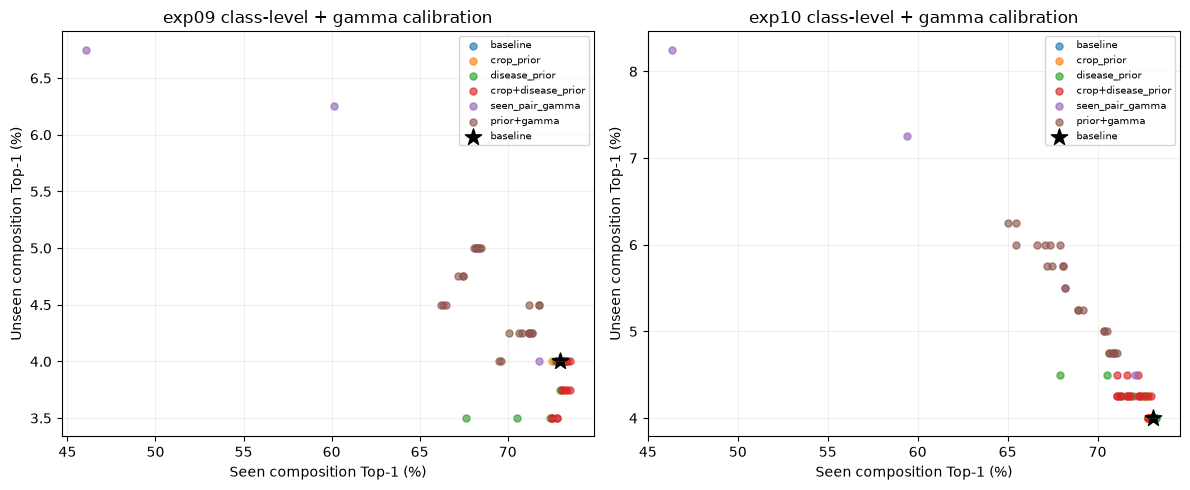

COMPLETE — saved: c:\AML\ML_Project\Baseline2\outputs\exp12_class_calibration
NO model training or official test accessed.


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,source in zip(axes,SOURCES):
    tab=results[results.source==source]
    for label,sub in tab.groupby('method',sort=False):
        ax.scatter(100*sub.full_val_seen_accuracy,100*sub.full_val_unseen_accuracy,
                   alpha=.65,s=26,label=label)
    base=tab[tab.method=='baseline'].iloc[0]
    ax.scatter([100*base.full_val_seen_accuracy],[100*base.full_val_unseen_accuracy],
               marker='*',s=150,color='black',label='baseline')
    ax.set_title(source+' class-level + gamma calibration')
    ax.set_xlabel('Seen composition Top-1 (%)');ax.set_ylabel('Unseen composition Top-1 (%)')
    ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUT_DIR/'calibration_seen_unseen_scatter.png',dpi=160)
plt.show()

# Training-only supports; per-class correct-rate comparisons on the same saved logits.
impact=[]
for source in SOURCES:
    base,best,mild=pick_settings(results,source)
    for label,row in [('baseline',base),('chosen_mild',mild),('chosen_high_HM',best)]:
        obj=raw[source]['val_unseen']
        pc, predicted_disease, _, head_disease=predict_pair(obj,row.crop_tau,row.disease_tau,row.gamma)
        truth=obj['disease_ids'];support=np.bincount(truth,minlength=175)
        corr=np.bincount(truth,weights=(head_disease==truth).astype(int),minlength=175)
        pair_correct=np.bincount(truth,weights=((pc==obj['crop_ids'])&(predicted_disease==truth)).astype(int),minlength=175)
        for d in np.where(support>0)[0]:
            impact.append({'source':source,'selection':label,'disease_id':int(d),
                           'train_images':int(disease_counts[d]),'unseen_support':int(support[d]),
                           'disease_correct':int(corr[d]),'disease_accuracy':float(corr[d]/support[d]),
                           'pair_correct':int(pair_correct[d]),'pair_accuracy':float(pair_correct[d]/support[d])})
per_class=pd.DataFrame(impact)
per_class.to_csv(OUT_DIR/'selected_per_disease_unseen.csv',index=False)

lines=['# Baseline 2 — Exp12 consolidated calibration and error findings','',
       '**Status:** Completed post-hoc scoring only; NO training, Stage 2, official test, or 333-pair restriction.',
       '**Sources:** Fixed Exp09 & Exp10 ResNet-50 stage-1 checkpoints via cached Exp11 development logits.',
       '**Important:** Calibration sweeps on reused development data are exploratory, not independent generalisation estimates.',
       '**Reproduction warning:** Exp11 logits give Exp10 seen 73.09% vs original training-time 73.24% (one image/695). New comparisons are internally consistent on cached logits.',
       '', '## Summary (full development; exploratory)']
for source in SOURCES:
    base,best,mild=pick_settings(results,source)
    def desc(x):
        return (f'{x.method} crop_tau={x.crop_tau:g}, disease_tau={x.disease_tau:g}, gamma={x.gamma:g}: '
                f'Seen {x.full_val_seen_accuracy:.2%}; Unseen {x.full_val_unseen_accuracy:.2%}; '
                f'HM {x.full_HM:.2%}')
    lines.extend([f'### {source}',f'- **Baseline:** {desc(base)}',
        f'- **Highest tune-subset HM:** {desc(best)}',
        f'- **Seen-preserving (≤2 pp tune Seen drop):** {desc(mild)}',
        f'- **Strict dual-improvement settings (full development):** '+str(int(results[(results.source==source)&results.full_strict_pareto.fillna(False)].shape[0])),
        '- See `selected_settings_internal_check.csv` for exploratory tune/check metrics and warnings.',''])
lines += ['## Explanation of the γ=6 mechanism',
          'A fixed seen-pair penalty changes only ranking: unseen candidates are promoted relative to training-seen candidates.',
          'It does not retrain the disease recognition head or add new symptom features.',
          'The table below counts actual examples recovered and broken (not merely net gain):','']
for _,r in transitions.iterrows():
    lines.append(f'- {r.source}/{r.split}: recovered {int(r.recovered)}, lost {int(r.lost)}, net {int(r.net_change)}')
lines += ['', '## Evidence files',
          '- `all_calibration_settings.csv`: complete prespecified grid across crop/disease prior adjustments and mild γ.',
          '- `selected_settings_internal_check.csv`: tune-subset choices and internal check-subset accuracy (NOT independent test).',
          '- `gamma6_prediction_transitions.csv` / `gamma6_transition_counts.csv`: corrected vs broken images.',
          '- `selected_per_disease_unseen.csv`: per-class disease and pair accuracy on held-out compositions.',
          '- `calibration_seen_unseen_scatter.png`: seen/unseen trade-offs.',
          '', '## Next controlled training experiments (NOT executed)',
          '1. Exp13: stronger disease-tempered sampling α=0.5 compared with Exp09/Exp10 (seed 42, all other settings held constant).',
          '2. Exp14: effective-number class-balanced disease loss (Cui et al.) without changing the natural shuffle sampler, separate experiment.',
          '3. Exp15+: fixed multi-seed verification (42, 123, 2026) for preselected promising settings; report mean±SD.',
          'Do NOT assume combining interventions improves results; isolate factors and validate on an independent protocol.',
          '', '## Current evidence in one sentence',
          'Exp10 tempered sampling barely changed development composition HM; Exp11 γ=6 raised unseen accuracy but substantially reduced seen accuracy. Exp12 investigates class-level corrections as a possible less destructive alternative.']
(OUT_DIR/'leader_experiment_hub_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('COMPLETE — saved:', OUT_DIR)
print('NO model training or official test accessed.')

## 8. Next training ablations — planned, NOT auto-run

**Do not mix the following into the Exp12 post-hoc Run All.** If you decide to run additional training, append a new controlled section to this **same Experiment Hub notebook** with a fresh `outputs/exp13/` or `outputs/exp14/` output folder. Keep the corresponding settings and checkpoint selection policy consistent with Exp09.

| Future study | Single factor changed relative to Exp09 | Why |
|---|---|---|
| Exp13 | WeightedRandomSampler disease α = 0.5 (instead of natural shuffle) | Test whether stronger balancing helps or overfits rare images |
| Exp14 | Effective-number disease loss weights while keeping natural shuffle | Test loss balancing separately from sampling |
| Exp15 | Multi-seed repeats for a **preselected** approach | Estimate stability, not cherry-pick the best seed |

**Why this design?** It preserves a one-notebook working environment while preventing an overnight Run All from silently launching multiple heavy GPU jobs or accessing official test data. The calibration experiments **actually run** above; these training studies are **only plans** until explicitly implemented.